<a href="https://colab.research.google.com/github/lydiateinfalt/Agent-Based-Modeling-Migration-and-Cognition/blob/main/Experiment2_External_Shock.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 2 – External economic shock
Reads the BehaviorSpace export of the shock experiment (spreadsheet **or** table format) and reproduces the before/after, composition, recovery and dose-response analyses. Time axis is the tick count (`[step]` in a spreadsheet export, `ticks` in a table export).

**Optional paired control.** The Experiment 1 sweep uses the same seeds and the same code up to the shock tick, so its runs are the no-shock counterfactual for every run here. Set `CONTROL_FILE` to that table export to get paired shock effects (Section 5); set it to `None` to skip.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import csv, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
plt.style.use('ggplot')

FILE = '/content/drive/MyDrive/Colab Notebooks/External Shock.csv' # <- Experiment 2 BehaviorSpace export (table, every 10 ticks)
CONTROL_FILE = '/content/drive/MyDrive/Colab Notebooks/Diaspora_sweep_v2.csv'     # <- Experiment 1 table export (no shock, same seeds) or None
SHOCK_TICK   = 793                           # last tick BEFORE the shock (go commands: go / if ticks = 794 [ apply-economic-shock ])
NET, DIA, SEED = 'network-strength', 'diaspora-signal', 'global-seed'
COLORS = ['cyan', 'green', 'yellow', 'red', 'orange']
LABEL  = {'cyan': 'cyan (voluntary non-migrant)', 'green': 'green (voluntary migrant)', 'yellow': 'yellow (acquiescent)',
          'red': 'red (trapped)', 'orange': 'orange (distressed migrant)'}
PLOT   = {'cyan': 'darkturquoise', 'green': 'forestgreen', 'yellow': 'gold', 'red': 'crimson', 'orange': 'darkorange'}

In [ ]:
def load_export(path):
    """Read a BehaviorSpace export, spreadsheet or table format, into one long DataFrame (one row per run and tick)."""
    rows = list(csv.reader(open(path, encoding='utf-8-sig')))
    if 'Spreadsheet' in ''.join(rows[0]):
        i_run = next(i for i, r in enumerate(rows) if r and r[0] == '[run number]')
        i_all = next(i for i, r in enumerate(rows) if r and r[0] == '[all run data]')
        hdr = rows[i_all][1:]
        starts = [j for j, h in enumerate(hdr) if h == '[step]']
        L = starts[1] - starts[0] if len(starts) > 1 else len(hdr)
        seen, names = {}, []
        for h in hdr[:L]:                               # a metric listed twice gets a '.1' suffix
            seen[h] = seen.get(h, -1) + 1
            names.append(h if seen[h] == 0 else f'{h}.{seen[h]}')
        params = {rows[j][0]: j for j in range(i_run + 1, i_all) if rows[j] and rows[j][0] and not rows[j][0].startswith('[')}
        body = np.array([r[1:] for r in rows[i_all + 1:] if len(r) > 1], dtype=object)
        out = []
        for k in range(len(hdr) // L):
            c0 = k * L
            b = pd.DataFrame(body[:, c0:c0 + L], columns=names).apply(pd.to_numeric, errors='coerce').dropna(subset=['[step]'])
            b['[run number]'] = int(rows[i_run][1 + c0])
            for p, j in params.items():
                b[p] = rows[j][1 + c0]
            out.append(b)
        d = pd.concat(out, ignore_index=True)
        for p in params:
            d[p] = d[p].map(_num)
        d = d.rename(columns={'[step]': 'ticks'})
    else:                                               # table export: 6 metadata lines, then the header
        d = pd.read_csv(path, skiprows=6)
        d.columns = [c.strip() for c in d.columns]
        if 'ticks' not in d.columns:
            d = d.rename(columns={'[step]': 'ticks'})
    dup = [c for c in d.columns if c.endswith('.1') and c[:-2] in d.columns]
    d = d.drop(columns=dup)                             # repeated metric columns
    d = d.rename(columns={c: c.split('=')[-1].strip(' ]') for c in d.columns if c.startswith('count turtles with [color')})
    d = d.rename(columns={c: 'fin-ability-orange' for c in d.columns if c.startswith('ifelse-value any? turtles with [color = orange]')})
    d = d.rename(columns={c: 'mean-asp-economic' for c in d.columns if c.strip() == 'mean [asp-economic] of turtles'})
    return d

def _num(v):
    try: return float(v)
    except (TypeError, ValueError): return v

d = load_export(FILE)
runs = d['[run number]'].nunique()
print(f"{len(d):,} rows | {runs} runs | rows/run {d.groupby('[run number]').size().unique()} | ticks {d.ticks.min():.0f}-{d.ticks.max():.0f}")
print('runs per arm:'); print(d.groupby([NET, DIA]).size().unstack().div(d.ticks.nunique()).rename_axis(index='network', columns='diaspora').astype(int))
assert d[SEED].nunique() * d[NET].nunique() * d[DIA].nunique() == runs, 'design is not fully crossed'
T_END = d.ticks.max()

# the shock must show up as one big drop in mean ability between two consecutive recorded ticks
rec_ticks = np.sort(d.ticks.unique())
T_PRE  = rec_ticks[rec_ticks <= SHOCK_TICK].max()       # last recorded tick before the shock
T_POST = rec_ticks[rec_ticks >  SHOCK_TICK].min()       # first recorded tick after it
drop_tick = d.groupby('ticks')['mean-ability-level'].mean().diff().idxmin()
print(f'recorded every {np.diff(rec_ticks).min():.0f} tick(s); largest drop in mean ability at tick {drop_tick:.0f}; snapshots: before = {T_PRE:.0f}, after = {T_POST:.0f}')
assert drop_tick == T_POST, 'SHOCK_TICK does not match the data'

180,300 rows | 300 runs | rows/run [601] | ticks 0-6000
runs per arm:
diaspora  0.00  0.25  0.50  1.00  2.00
network                               
0.0         30    30    30    30    30
0.4         30    30    30    30    30
recorded every 10 tick(s); largest drop in mean ability at tick 800; snapshots: before = 790, after = 800


In [ ]:
d

,[run number],initial-ability-level,network-strength,num-turtles,show-links,initial-aspiration-level,max-links,global-seed,diaspora-signal,[step],...,cumulative-peer-pressure,cumulative-diaspora-pull,cumulative-exits,fin-ability-orange,mean-asp-economic,cyan,green,yellow,red,orange
0,3,All,0.0,200,False,All,2,1,0.50,0,...,0.00,0.000,0,6.210915,5.193246,28,23,30,68,51
1,4,All,0.0,200,False,All,2,1,1.00,0,...,0.00,0.000,0,6.210915,5.193246,28,23,30,68,51
2,9,All,0.0,200,False,All,2,2,1.00,0,...,0.00,0.000,0,6.168732,5.064180,19,20,33,83,45
3,2,All,0.0,200,False,All,2,1,0.25,0,...,0.00,0.000,0,6.210915,5.193246,28,23,30,68,51
4,5,All,0.0,200,False,All,2,1,2.00,0,...,0.00,0.000,0,6.210915,5.193246,28,23,30,68,51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180295,300,All,0.4,200,False,All,2,30,2.00,596,...,10.96,1418.218,65,4.270761,7.817558,1,61,1,107,30
180296,300,All,0.4,200,False,All,2,30,2.00,597,...,10.96,1420.838,65,4.261260,7.817558,1,61,1,107,30
180297,300,All,0.4,200,False,All,2,30,2.00,598,...,10.96,1423.458,65,4.256902,7.817558,1,61,1,107,30
180298,300,All,0.4,200,False,All,2,30,2.00,599,...,10.96,1426.078,65,4.256861,7.817558,1,61,1,107,30


## 1. What the shock does at once (tick before vs tick after)
Same runs, the last recorded tick before the shock and the first after it. With 10-tick recording the gap includes six ordinary ticks of growth, so the change is almost entirely the shock.

In [ ]:
snap_cols = ['mean-aspiration-level', 'mean-ability-level', 'share-high-ability', 'mean-asp-social', 'mobility-zone-share',
             'unique-migrants', 'cumulative-migrations', 'cumulative-exits'] + COLORS
snap_cols += [c for c in ('mean-asp-economic', 'fin-ability-orange') if c in d.columns]
a = d[d.ticks == T_PRE].set_index('[run number]')[snap_cols]
b = d[d.ticks == T_POST].set_index('[run number]')[snap_cols]
snap = pd.DataFrame({'before': a.mean(), 'after': b.mean()})
snap['change'] = snap.after - snap.before
snap['change_%'] = 100 * snap.change / snap.before
snap['p_paired_t'] = [stats.ttest_rel(b[c], a[c]).pvalue if (b[c] - a[c]).std() > 0 else np.nan for c in snap_cols]
snap.assign(p_paired_t=snap.p_paired_t.map('{:.1e}'.format)).round(3)

,before,after,change,change_%,p_paired_t
mean-aspiration-level,6.378,6.644,0.266,4.175,0.0e+00
mean-ability-level,5.658,4.256,-1.402,-24.776,0.0e+00
share-high-ability,0.643,0.386,-0.257,-40.000,2.7e-263
mean-asp-social,5.279,5.304,0.025,0.472,5.5e-48
mobility-zone-share,0.488,0.295,-0.192,-39.421,1.1e-210
unique-migrants,22.727,30.977,8.250,36.301,2.7e-151
cumulative-migrations,31.620,40.043,8.423,26.639,4.5e-156
cumulative-exits,9.333,56.200,46.867,502.143,7.6e-258
cyan,31.147,18.123,-13.023,-41.813,6.0e-173
green,34.253,37.810,3.557,10.383,1.8e-42


## 2. Time course across the whole run

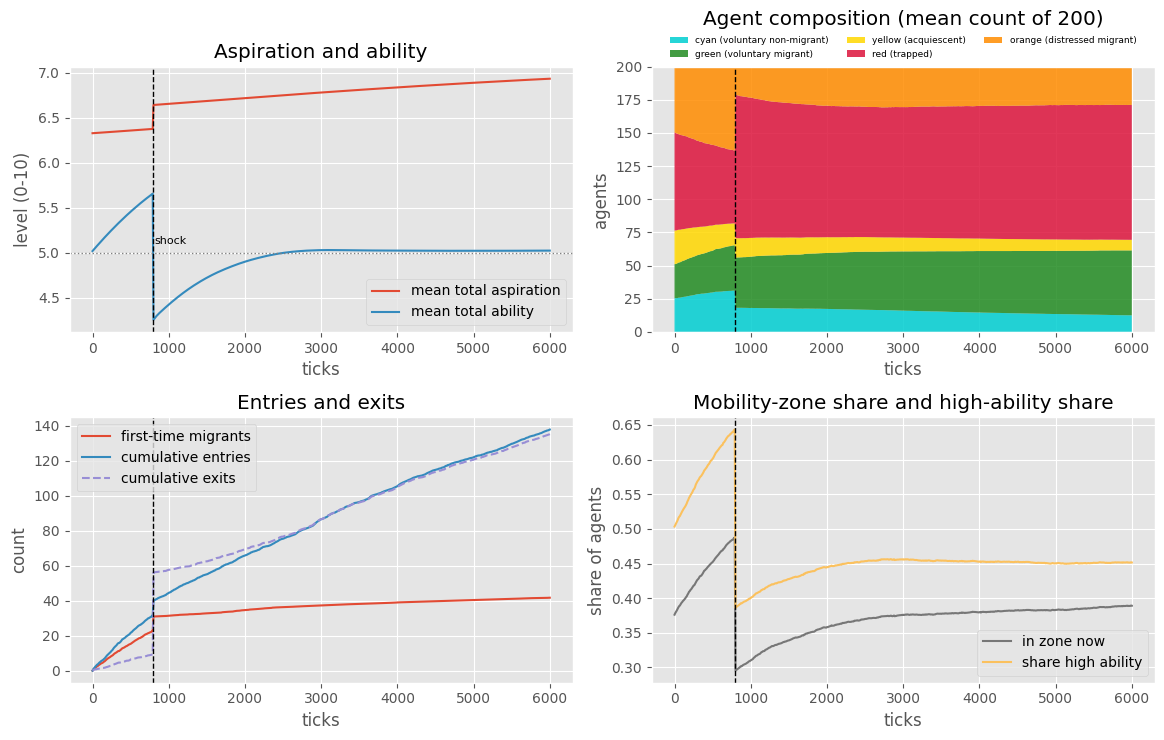

In [ ]:
G = d.groupby('ticks')[['mean-aspiration-level', 'mean-ability-level', 'share-high-ability', 'mobility-zone-share',
                        'unique-migrants', 'cumulative-migrations', 'cumulative-exits'] + COLORS].mean()

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
ax = axes[0, 0]
ax.plot(G.index, G['mean-aspiration-level'], label='mean total aspiration'); ax.plot(G.index, G['mean-ability-level'], label='mean total ability')
ax.axhline(5, color='grey', ls=':', lw=1); ax.set_title('Aspiration and ability'); ax.set_ylabel('level (0-10)'); ax.legend(loc='lower right')
ax = axes[0, 1]
ax.stackplot(G.index, *[G[c] for c in COLORS], colors=[PLOT[c] for c in COLORS], labels=[LABEL[c] for c in COLORS], alpha=.85)
ax.set_title('Agent composition (mean count of 200)', pad=30); ax.set_ylabel('agents'); ax.legend(loc='lower center', bbox_to_anchor=(.5, 1.0), ncol=3, fontsize=6.5, frameon=False); ax.set_ylim(0, 200)
ax = axes[1, 0]
ax.plot(G.index, G['unique-migrants'], label='first-time migrants'); ax.plot(G.index, G['cumulative-migrations'], label='cumulative entries')
ax.plot(G.index, G['cumulative-exits'], label='cumulative exits', ls='--'); ax.set_title('Entries and exits'); ax.set_ylabel('count'); ax.legend(loc='upper left')
ax = axes[1, 1]
ax.plot(G.index, G['mobility-zone-share'], color='C3', label='in zone now'); ax.plot(G.index, G['share-high-ability'], color='C4', label='share high ability')
ax.set_title('Mobility-zone share and high-ability share'); ax.set_ylabel('share of agents'); ax.legend(loc='lower right')
for ax in axes.ravel():
    ax.axvline(SHOCK_TICK, color='k', ls='--', lw=1); ax.set_xlabel('ticks')
axes[0, 0].text(SHOCK_TICK + 15, 5.1, 'shock', fontsize=8)
plt.tight_layout(); plt.show()

## 3. Who is moved by the shock? Composition before, after and at the end

In [ ]:
comp = G.loc[[T_PRE, T_POST, T_END], COLORS].T
comp.columns = ['before shock', 'just after', 'end of run']
comp['shock change'] = comp['just after'] - comp['before shock']
comp['recovered by end'] = comp['end of run'] - comp['just after']
comp.rename(index=LABEL).round(1)

,before shock,just after,end of run,shock change,recovered by end
cyan (voluntary non-migrant),31.1,18.1,12.5,-13.0,-5.6
green (voluntary migrant),34.3,37.8,49.0,3.6,11.1
yellow (acquiescent),16.5,14.7,8.0,-1.8,-6.7
red (trapped),54.8,108.1,101.7,53.3,-6.4
orange (distressed migrant),63.3,21.3,28.9,-42.0,7.6


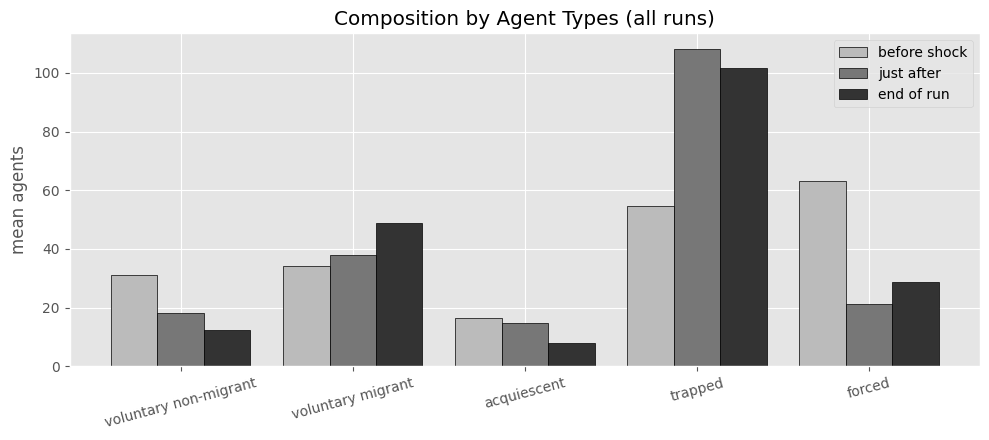

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(COLORS)); w = .27
for i, (col, lab) in enumerate(zip(['before shock', 'just after', 'end of run'], ['before shock', 'just after', 'end of run'])):
    ax.bar(x + (i - 1) * w, comp[col].values, w, label=lab, edgecolor='black', color=['#bbbbbb', '#777777', '#333333'][i])

# Map colors to translated descriptive labels
translated_labels = [
    'voluntary non-migrant' if c == 'cyan' else
    'voluntary migrant' if c == 'green' else
    'acquiescent' if c == 'yellow' else
    'trapped' if c == 'red' else
    'forced' for c in COLORS
]

ax.set_xticks(x)
ax.set_xticklabels(translated_labels, rotation=15)
ax.set_ylabel('mean agents')
ax.set_title('Composition by Agent Types (all runs)')
ax.legend()
plt.tight_layout()
plt.show()

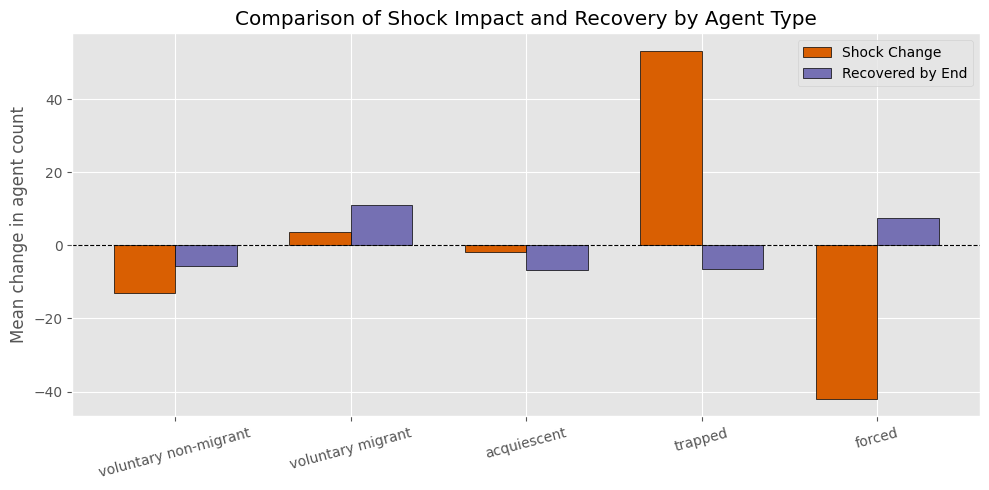

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Prepare data
labels = [
    'voluntary non-migrant' if c == 'cyan' else
    'voluntary migrant' if c == 'green' else
    'acquiescent' if c == 'yellow' else
    'trapped' if c == 'red' else
    'forced' for c in comp.index
]

shock_change = comp['shock change'].values
recovered = comp['recovered by end'].values

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - width/2, shock_change, width, label='Shock Change', color='#d95f02', edgecolor='black')
rects2 = ax.bar(x + width/2, recovered, width, label='Recovered by End', color='#7570b3', edgecolor='black')

# Add details
ax.set_ylabel('Mean change in agent count')
ax.set_title('Comparison of Shock Impact and Recovery by Agent Type')
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=15)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Create a dictionary to map raw color columns to translated agent types
rename_dict = {
    'cyan': 'voluntary non-migrant',
    'green': 'voluntary migrant',
    'yellow': 'acquiescent',
    'red': 'trapped',
    'orange': 'forced'
}

# Calculate correlation matrix
corr_cols = COLORS + ['mean-aspiration-level', 'mean-ability-level']
correlation_matrix = d[corr_cols].corr()

# Rename the index/columns to translated labels and select target columns
correlation_results = correlation_matrix.rename(index=rename_dict, columns=rename_dict)[['mean-aspiration-level', 'mean-ability-level']].loc[rename_dict.values()]

# Display the formatted correlation table
display(correlation_results.round(3))

,mean-aspiration-level,mean-ability-level
voluntary non-migrant,-0.913,0.359
voluntary migrant,0.727,0.044
acquiescent,-0.798,0.086
trapped,0.682,-0.725
forced,-0.414,0.617


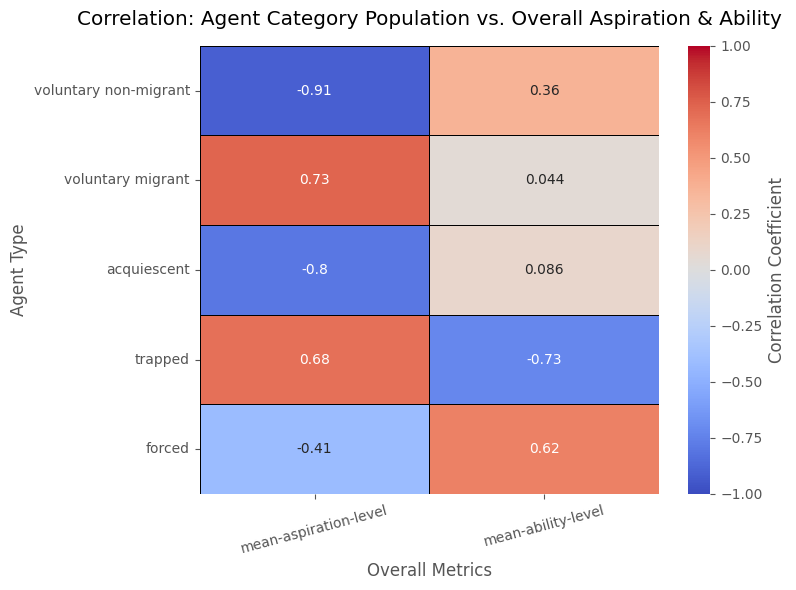

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set up the plotting style
plt.style.use('ggplot')
fig, ax = plt.subplots(figsize=(8, 6))

# Create heatmap
sns.heatmap(
    correlation_results,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor='black',
    cbar_kws={'label': 'Correlation Coefficient'},
    ax=ax
)

# Add titles and formatting
ax.set_title('Correlation: Agent Category Population vs. Overall Aspiration & Ability', pad=15)
ax.set_xlabel('Overall Metrics')
ax.set_ylabel('Agent Type')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 4. Recovery after the shock
How much of the one-tick loss in ability and aspiration has been regained by the end of the run? Ability can regain only through human-capital growth and savings; in these runs the shock-raised aspiration does not decay.

In [ ]:
rec = []
for m in ['mean-ability-level', 'share-high-ability', 'mean-aspiration-level', 'mobility-zone-share', 'red', 'orange']:
    pre, post, end = G.loc[T_PRE, m], G.loc[T_POST, m], G.loc[T_END, m]
    rec.append(dict(metric=m, before=pre, just_after=post, end=end, shock_change=post - pre,
                    share_of_shock_undone_by_end=(end - post) / (pre - post) if pre != post else np.nan))
pd.DataFrame(rec).set_index('metric').round(3)

,before,just_after,end,shock_change,share_of_shock_undone_by_end
metric,,,,,
mean-ability-level,5.658,4.256,5.026,-1.402,0.549
share-high-ability,0.643,0.386,0.451,-0.257,0.255
mean-aspiration-level,6.378,6.644,6.936,0.266,-1.095
mobility-zone-share,0.488,0.295,0.389,-0.192,0.487
red,54.807,108.093,101.713,53.287,0.120
orange,63.267,21.267,28.867,-42.000,0.181


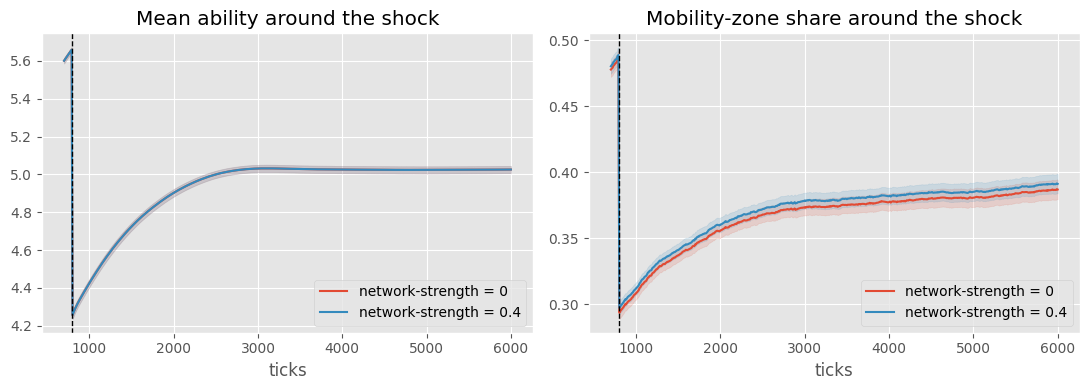

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
Z = d[(d.ticks >= SHOCK_TICK - 100)]
for ax, m, t in zip(axes, ['mean-ability-level', 'mobility-zone-share'], ['Mean ability', 'Mobility-zone share']):
    for n, c in zip(sorted(d[NET].unique()), ['C0', 'C1']):
        z = Z[Z[NET] == n].groupby('ticks')[m].agg(['mean', 'sem'])
        ax.plot(z.index, z['mean'], color=c, label=f'network-strength = {n:g}'); ax.fill_between(z.index, z['mean'] - 1.96 * z['sem'], z['mean'] + 1.96 * z['sem'], color=c, alpha=.15)
    ax.axvline(SHOCK_TICK, color='k', ls='--', lw=1); ax.set_title(t + ' around the shock'); ax.set_xlabel('ticks'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

## 5. Paired shock effect against the no-shock control
Same seed, same arm, with and without the shock (control = Experiment 1 export). Positive means the shock raised the value.

In [ ]:
HAVE_CTRL = CONTROL_FILE is not None
if HAVE_CTRL:
    c = load_export(CONTROL_FILE)
    METR = ['unique-migrants', 'cumulative-migrations', 'cumulative-exits', 'mean-ability-level', 'mean-aspiration-level', 'mobility-zone-share'] + COLORS
    METR = [m for m in METR if m in c.columns]
    def wide(df, m): return df.pivot_table(index=[NET, DIA, SEED], columns='ticks', values=m)
    common = sorted(set(d.ticks) & set(c.ticks))
    EFF = {m: wide(d, m)[common] - wide(c, m).reindex(wide(d, m).index)[common] for m in METR}
    pre = [t for t in common if t <= SHOCK_TICK]
    worst = max(EFF[m][pre].abs().max().max() for m in ['unique-migrants', 'mean-ability-level'])
    print(f'control ticks in common: {len(common)} | max pre-shock difference (must be 0): {worst}')
    assert worst == 0, 'control runs differ from the shock runs before the shock: not the same code/seeds'
else:
    print('CONTROL_FILE is None: Sections 5-6 skipped')

control ticks in common: 601 | max pre-shock difference (must be 0): 0.0


In [ ]:
if HAVE_CTRL:
    CHECK = [t for t in (T_POST, 900, 1000, 1200, 1500, 2000, 3000, 4000, 5000, T_END) if t in common]
    def boot(x, n=5000):
        rng = np.random.default_rng(0); x = np.asarray(x)
        bs = x[rng.integers(0, len(x), (n, len(x)))].mean(1)
        return np.percentile(bs, [2.5, 97.5])
    rows = []
    for m in METR:
        for t in CHECK:
            x = EFF[m][t].values; lo, hi = boot(x)
            rows.append(dict(metric=m, tick=t, shock_effect=x.mean(), lo=lo, hi=hi))
    eff_tab = pd.DataFrame(rows)
    display(eff_tab.pivot(index='metric', columns='tick', values='shock_effect').loc[METR].round(2))

tick,800,900,1000,1200,1500,2000,3000,4000,5000,6000
metric,,,,,,,,,,
unique-migrants,7.86,6.09,4.25,0.51,-4.11,-8.87,-11.32,-12.55,-13.88,-15.13
cumulative-migrations,7.97,6.93,5.58,3.83,-0.16,-1.65,2.42,9.58,11.58,10.03
cumulative-exits,46.80,45.90,45.13,44.20,42.23,41.83,44.70,51.53,54.07,52.90
mean-ability-level,-1.41,-1.37,-1.35,-1.31,-1.26,-1.21,-1.10,-1.09,-1.08,-1.07
mean-aspiration-level,0.27,0.27,0.27,0.27,0.26,0.26,0.26,0.26,0.26,0.26
mobility-zone-share,-0.19,-0.19,-0.20,-0.20,-0.21,-0.22,-0.21,-0.21,-0.21,-0.21
cyan,-13.04,-13.69,-14.15,-14.99,-15.60,-15.68,-14.76,-13.91,-13.01,-12.33
green,3.37,2.93,2.41,1.29,-0.60,-2.15,-3.38,-4.32,-5.36,-6.14
yellow,-1.78,-1.08,-0.51,0.49,1.46,1.91,1.74,1.52,1.39,1.32


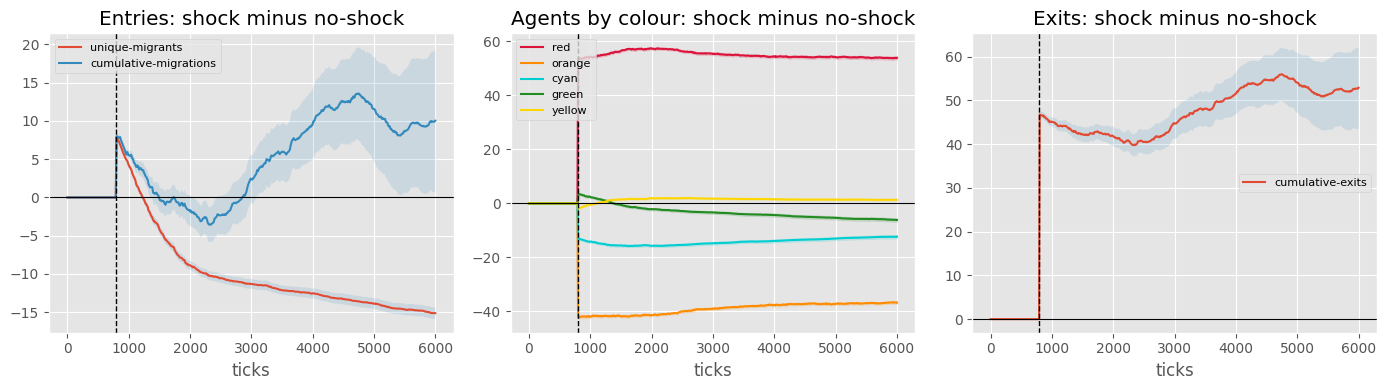

In [ ]:
if HAVE_CTRL:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, ms, ttl in zip(axes, [['unique-migrants', 'cumulative-migrations'], ['red', 'orange', 'cyan', 'green', 'yellow'], ['cumulative-exits']],
                           ['Entries: shock minus no-shock', 'Agents by colour: shock minus no-shock', 'Exits: shock minus no-shock']):
        for m in ms:
            e = EFF[m]; mu = e.mean(); se = e.std() / np.sqrt(len(e))
            ax.plot(mu.index, mu.values, label=m, color=PLOT.get(m)); ax.fill_between(mu.index, mu - 1.96 * se, mu + 1.96 * se, alpha=.15, color=PLOT.get(m))
        ax.axhline(0, color='k', lw=.8); ax.axvline(SHOCK_TICK, color='k', ls='--', lw=1); ax.set_title(ttl); ax.set_xlabel('ticks'); ax.legend(loc='best', fontsize=8)
    plt.tight_layout(); plt.show()

In [ ]:
if HAVE_CTRL:
    # when does the shock-induced extra entry turn into a deficit?
    mu = EFF['unique-migrants'].mean()
    after = mu[mu.index > SHOCK_TICK]
    print('extra first-time migrants right after the shock:', round(after.iloc[0], 2), '| peak:', round(after.max(), 2), 'at tick', after.idxmax())
    cross = after[after <= 0]
    print('first tick the shock effect on first-time migrants is <= 0:', cross.index[0] if len(cross) else 'never within the run')
    print('effect at last common tick:', round(mu.iloc[-1], 2), '| cumulative entries:', round(EFF['cumulative-migrations'].mean().iloc[-1], 2),
          '| exits:', round(EFF['cumulative-exits'].mean().iloc[-1], 2))

extra first-time migrants right after the shock: 7.86 | peak: 7.86 at tick 800
first tick the shock effect on first-time migrants is <= 0: 1230
effect at last common tick: -15.13 | cumulative entries: 10.03 | exits: 52.9


## 6. Shock effect by arm (diaspora signal × network strength)

In [ ]:
if HAVE_CTRL:
    t_last = max(common)
    rows = []
    for (n, dv), grp in EFF['unique-migrants'].groupby(level=[0, 1]):
        r = dict(net=n, dia=dv)
        for m in ['unique-migrants', 'cumulative-migrations', 'red', 'orange']:
            r[f'{m} @{CHECK[0]}'] = EFF[m].loc[grp.index, CHECK[0]].mean()
            r[f'{m} @{t_last}'] = EFF[m].loc[grp.index, t_last].mean()
        rows.append(r)
    display(pd.DataFrame(rows).round(2))

,net,dia,unique-migrants @800,unique-migrants @6000,cumulative-migrations @800,cumulative-migrations @6000,red @800,red @6000,orange @800,orange @6000
0,0.0,0.00,8.07,-9.27,8.17,15.83,53.43,51.87,-42.2,-36.73
1,0.0,0.25,7.73,-11.33,7.83,13.77,53.47,52.70,-42.2,-36.73
2,0.0,0.50,7.87,-13.63,7.97,11.47,53.30,53.43,-42.2,-36.73
3,0.0,1.00,7.80,-16.97,7.90,8.20,53.73,54.97,-42.2,-36.73
4,0.0,2.00,7.27,-22.60,7.37,2.67,53.57,56.23,-42.2,-36.73
5,0.4,0.00,8.17,-9.90,8.33,15.23,53.77,52.10,-42.2,-36.73
6,0.4,0.25,8.07,-12.47,8.17,12.67,53.73,52.83,-42.2,-36.73
7,0.4,0.50,8.30,-14.33,8.40,10.80,53.57,53.50,-42.2,-36.73
8,0.4,1.00,7.97,-17.90,8.07,7.30,53.97,55.00,-42.2,-36.73
9,0.4,2.00,7.40,-22.90,7.50,2.37,53.90,56.20,-42.2,-36.73


## 7. Does the diaspora pull still act after the shock? (paired by seed, against signal = 0)

In [ ]:
def wide_d(m): return d.pivot_table(index=[NET, DIA, SEED], columns='ticks', values=m)
U = wide_d('unique-migrants'); C = wide_d('cumulative-migrations')

def paired(P, n, dv, t, base=0.0):
    x = (P.loc[(n, dv), t] - P.loc[(n, base), t]).values
    rng = np.random.default_rng(0); bs = x[rng.integers(0, len(x), (5000, len(x)))].mean(1)
    return dict(net=n, dia=dv, tick=t, gain=x.mean(), lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5),
                p_t=stats.ttest_rel(P.loc[(n, dv), t], P.loc[(n, base), t]).pvalue)

dose = pd.DataFrame([paired(U, n, dv, t) for t in (T_PRE, T_END) for n in sorted(d[NET].unique()) for dv in sorted(d[DIA].unique()) if dv > 0])
dose.assign(p_t=dose.p_t.map('{:.1e}'.format)).round(3)

,net,dia,tick,gain,lo,hi,p_t
0,0.0,0.25,790,0.633,0.333,1.000,1.2e-03
1,0.0,0.50,790,1.233,0.733,1.867,2.8e-04
2,0.0,1.00,790,2.333,1.833,2.900,3.7e-09
3,0.0,2.00,790,4.200,3.500,4.967,6.0e-12
4,0.4,0.25,790,0.500,0.200,0.933,1.4e-02
5,0.4,0.50,790,0.933,0.467,1.533,2.3e-03
6,0.4,1.00,790,2.333,1.800,2.967,1.9e-08
7,0.4,2.00,790,4.100,3.367,4.900,4.2e-11
8,0.0,0.25,6000,3.900,3.233,4.633,1.6e-11
9,0.0,0.50,6000,7.200,6.200,8.300,9.5e-14


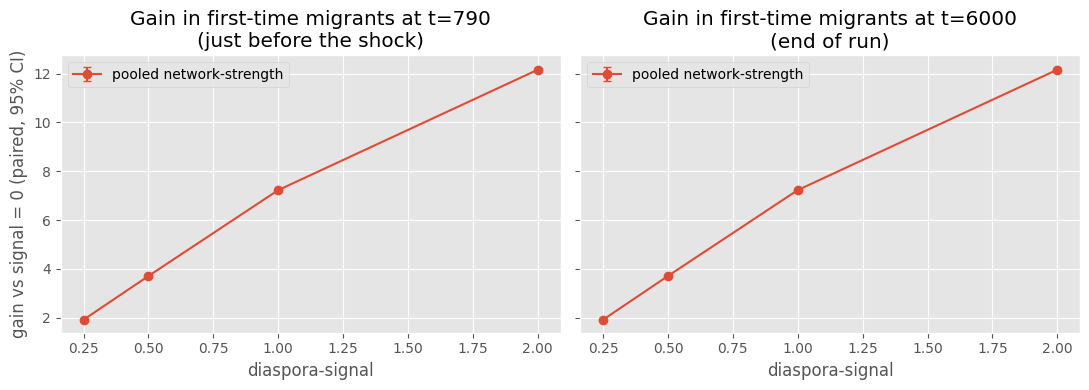

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Recalculate paired gain pooling across network-strengths for simplicity
def paired_pooled(P, dv, t, base=0.0):
    # Pool the values across all network strengths for the given diaspora-signal and seed
    active = P.xs(dv, level=DIA).values.flatten()
    baseline = P.xs(base, level=DIA).values.flatten()
    x = active - baseline
    rng = np.random.default_rng(0)
    bs = x[rng.integers(0, len(x), (5000, len(x)))].mean(1)
    return dict(dia=dv, tick=t, gain=x.mean(), lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5))

dose_pooled = pd.DataFrame([paired_pooled(U, dv, t) for t in (T_PRE, T_END) for dv in sorted(d[DIA].unique()) if dv > 0])

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, t, ttl in zip(axes, (T_PRE, T_END), ('just before the shock', 'end of run')):
    s = dose_pooled[dose_pooled.tick == t]
    ax.errorbar(s.dia, s.gain, yerr=[s.gain - s.lo, s.hi - s.gain], marker='o', capsize=3, color='C0', label='pooled network-strength')
    ax.set_title(f'Gain in first-time migrants at t={t:.0f}\n({ttl})')
    ax.set_xlabel('diaspora-signal')
    ax.legend(loc='upper left')

axes[0].set_ylabel('gain vs signal = 0 (paired, 95% CI)')
plt.tight_layout()
plt.show()

In [ ]:
# Entries after the shock only: increase from the post-shock tick to the end, by arm
post = pd.DataFrame({'first-time migrants after shock': (U[T_END] - U[T_POST]), 'cumulative entries after shock': (C[T_END] - C[T_POST])})
post.groupby([NET, DIA]).mean().round(2)

first-time migrants after shock  \
network-strength diaspora-signal                                    
0.0              0.00                                        3.00   
                 0.25                                        6.60   
                 0.50                                        9.17   
                 1.00                                       14.97   
                 2.00                                       19.80   
0.4              0.00                                        3.30   
                 0.25                                        6.43   
                 0.50                                        9.63   
                 1.00                                       15.20   
                 2.00                                       19.40   

                                  cumulative entries after shock  
network-strength diaspora-signal                                  
0.0              0.00                                      90.07  
                 0.25                                      93.67  
                 0.50                                      96.23  
                 1.00                                     102.10  
                 2.00                                     107.03  
0.4              0.00                                      90.37  
                 0.25                                      93.53  
                 0.50                                      96.73  
                 1.00                                     102.37  
                 2.00                                     106.63

## 8. Agent colours at the end of the run, by diaspora signal

In [ ]:
fin = d[d.ticks == T_END].groupby([NET, DIA])[COLORS + ['unique-migrants', 'mean-aspiration-level', 'mean-ability-level']].mean().round(2)
fin

cyan  green  yellow     red  orange  \
network-strength diaspora-signal                                         
0.0              0.00             21.93  39.50   13.90   95.80   28.87   
                 0.25             18.03  43.40   11.40   98.30   28.87   
                 0.50             14.73  46.70    9.33  100.37   28.87   
                 1.00              7.97  53.47    5.43  104.27   28.87   
                 2.00              1.90  59.53    1.03  108.67   28.87   
0.4              0.00             20.87  40.57   13.23   96.47   28.87   
                 0.25             17.30  44.13   10.80   98.90   28.87   
                 0.50             13.47  47.97    8.90  100.80   28.87   
                 1.00              6.97  54.47    4.87  104.83   28.87   
                 2.00              1.67  59.77    0.97  108.73   28.87   

                                  unique-migrants  mean-aspiration-level  \
network-strength diaspora-signal                                           
0.0              0.00                       32.20                   6.59   
                 0.25                       36.10                   6.71   
                 0.50                       39.40                   6.84   
                 1.00                       46.27                   7.07   
                 2.00                       52.43                   7.39   
0.4              0.00                       33.27                   6.62   
                 0.25                       36.83                   6.75   
                 0.50                       40.67                   6.87   
                 1.00                       47.33                   7.10   
                 2.00                       52.77                   7.42   

                                  mean-ability-level  
network-strength diaspora-signal                      
0.0              0.00                           5.03  
                 0.25                           5.03  
                 0.50                           5.03  
                 1.00                           5.03  
                 2.00                           5.03  
0.4              0.00                           5.03  
                 0.25                           5.03  
                 0.50                           5.03  
                 1.00                           5.03  
                 2.00                           5.03

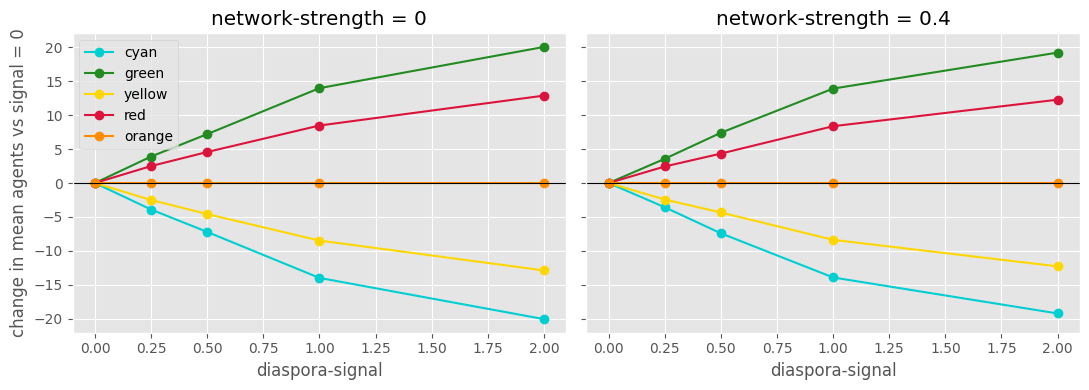

In [ ]:
# change in colour counts relative to signal = 0 (same network setting), end of run
fm = d[d.ticks == T_END].groupby([NET, DIA])[COLORS].mean()
chg = fm.sub(fm.xs(0.0, level=DIA), level=NET)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, n in zip(axes, sorted(d[NET].unique())):
    for col in COLORS:
        ax.plot(chg.loc[n].index, chg.loc[n, col], 'o-', color=PLOT[col], label=col)
    ax.axhline(0, color='k', lw=.8); ax.set_title(f'network-strength = {n:g}'); ax.set_xlabel('diaspora-signal')
axes[0].set_ylabel('change in mean agents vs signal = 0'); axes[0].legend(loc='best')
plt.tight_layout(); plt.show()

## 9. Phase table for the write-up
Mean over all runs, and over the active-social runs only (diaspora-signal > 0 and network-strength > 0).

In [ ]:
pts = {'before shock': T_PRE, 'just after shock': T_POST, 'T + 400': T_POST + 400, 'T + 2000': T_POST + 2000, 'end of run': T_END}
act = d[(d[DIA] > 0) & (d[NET] > 0)]
cols_ = ['unique-migrants', 'cumulative-migrations', 'cumulative-exits', 'mean-aspiration-level', 'mean-ability-level', 'mobility-zone-share']
if 'mean-asp-economic' in d.columns:
    cols_.append('mean-asp-economic')
out = {}
for name, df_ in (('all runs', d), ('diaspora > 0 and network > 0', act)):
    out[name] = pd.DataFrame({k: df_[df_.ticks == t][cols_].mean() for k, t in pts.items()})
pd.concat(out, axis=1).round(2)

all runs                                    \
                      before shock just after shock T + 400 T + 2000   
unique-migrants              22.73            30.98   32.05    36.93   
cumulative-migrations        31.62            40.04   49.36    81.27   
cumulative-exits              9.33            56.20   59.43    81.60   
mean-aspiration-level         6.38             6.64    6.67     6.77   
mean-ability-level            5.66             4.26    4.56     5.02   
mobility-zone-share           0.49             0.30    0.33     0.37   
mean-asp-economic             5.00             7.85    7.85     7.85   

                                 diaspora > 0 and network > 0  \
                      end of run                 before shock   
unique-migrants            41.73                        23.40   
cumulative-migrations     137.92                        32.37   
cumulative-exits          135.33                         9.40   
mean-aspiration-level       6.94                         6.40   
mean-ability-level          5.03                         5.66   
mobility-zone-share         0.39                         0.49   
mean-asp-economic           7.85                         5.00   

                                                                    
                      just after shock T + 400 T + 2000 end of run  
unique-migrants                  31.73   33.00    38.69      44.40  
cumulative-migrations            40.87   50.38    83.11     140.68  
cumulative-exits                 56.33   59.57    81.73     135.47  
mean-aspiration-level             6.67    6.70     6.83       7.03  
mean-ability-level                4.26    4.56     5.02       5.03  
mobility-zone-share               0.30    0.33     0.38       0.40  
mean-asp-economic                 7.85    7.85     7.85       7.85

## 10. Economic aspiration and distressed migrants' financial ability
Needs the two extra reporters (`mean [asp-economic] of turtles` and the guarded mean of `abil-financial` over orange agents). The orange figure is a mean over whoever is orange *at that tick*, so the group changes when the shock pushes agents out of orange.

economic aspiration: 5.00 -> 7.85 (+2.85, 57.2%)
mean total ability: 5.66 -> 4.26 (-24.8%)
financial ability of orange agents: 5.17 -> 6.56 | orange agents 63.3 -> 21.3


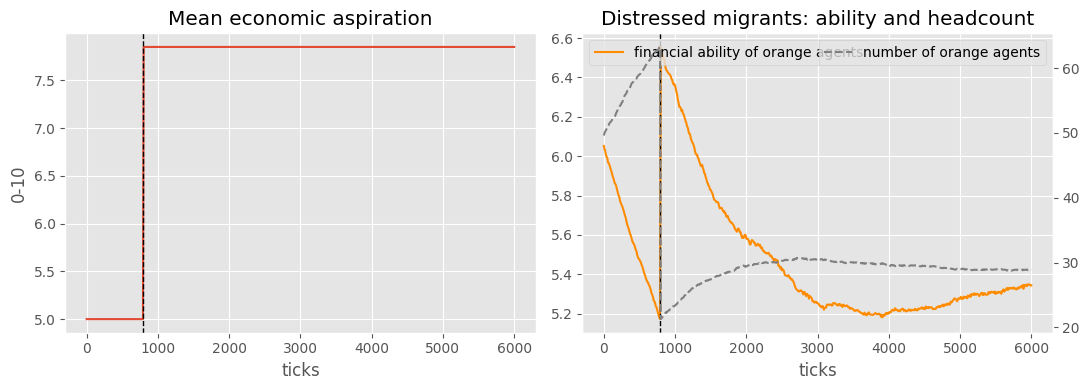

In [ ]:
if 'mean-asp-economic' in d.columns:
    X = d.groupby('ticks')[['mean-asp-economic', 'fin-ability-orange', 'orange', 'mean-ability-level']].mean()
    a = d[d.ticks == T_PRE].set_index('[run number]'); b = d[d.ticks == T_POST].set_index('[run number]')
    print(f"economic aspiration: {a['mean-asp-economic'].mean():.2f} -> {b['mean-asp-economic'].mean():.2f} "
          f"(+{(b['mean-asp-economic'] - a['mean-asp-economic']).mean():.2f}, {100 * (b['mean-asp-economic'] / a['mean-asp-economic'] - 1).mean():.1f}%)")
    print(f"mean total ability: {a['mean-ability-level'].mean():.2f} -> {b['mean-ability-level'].mean():.2f} ({100 * (b['mean-ability-level'].mean() / a['mean-ability-level'].mean() - 1):.1f}%)")
    print(f"financial ability of orange agents: {a['fin-ability-orange'].mean():.2f} -> {b['fin-ability-orange'].mean():.2f} | orange agents {a['orange'].mean():.1f} -> {b['orange'].mean():.1f}")
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(X.index, X['mean-asp-economic']); axes[0].set_title('Mean economic aspiration'); axes[0].set_ylabel('0-10')
    axes[1].plot(X.index, X['fin-ability-orange'], color=PLOT['orange'], label='financial ability of orange agents')
    ax2 = axes[1].twinx(); ax2.plot(X.index, X['orange'], color='grey', ls='--', label='number of orange agents'); ax2.grid(False)
    axes[1].set_title('Distressed migrants: ability and headcount'); axes[1].legend(loc='upper left'); ax2.legend(loc='upper right')
    for ax in axes: ax.axvline(SHOCK_TICK, color='k', ls='--', lw=1); ax.set_xlabel('ticks')
    plt.tight_layout(); plt.show()
else:
    print('economic-aspiration / orange-ability reporters not in this export')

## Notes on what the export does and does not contain
* The shock raises each agent's economic aspiration by 2 to 5 and lowers every ability component by 0.3 × (11 − financial ability); the export records only the population means, so the paper's earlier group-level figures (for example distressed migrants' financial ability before and after) need an extra reporter, such as `mean [abil-financial] of turtles with [color = orange]`.
* The shock is applied once, when `ticks = SHOCK_TICK + 1` (794), to every arm, so the arms differ only in `diaspora-signal` and `network-strength`.
* Without `CONTROL_FILE` there is no no-shock comparison inside this file; before/after changes then mix the shock with ordinary growth.

In [ ]:
from PIL import Image
from IPython.display import display

try:
    img = Image.open('/content/Picture1.png')
    display(img)
except Exception as e:
    print(f'Error loading image: {e}')

Error loading image: [Errno 2] No such file or directory: '/content/Picture1.png'


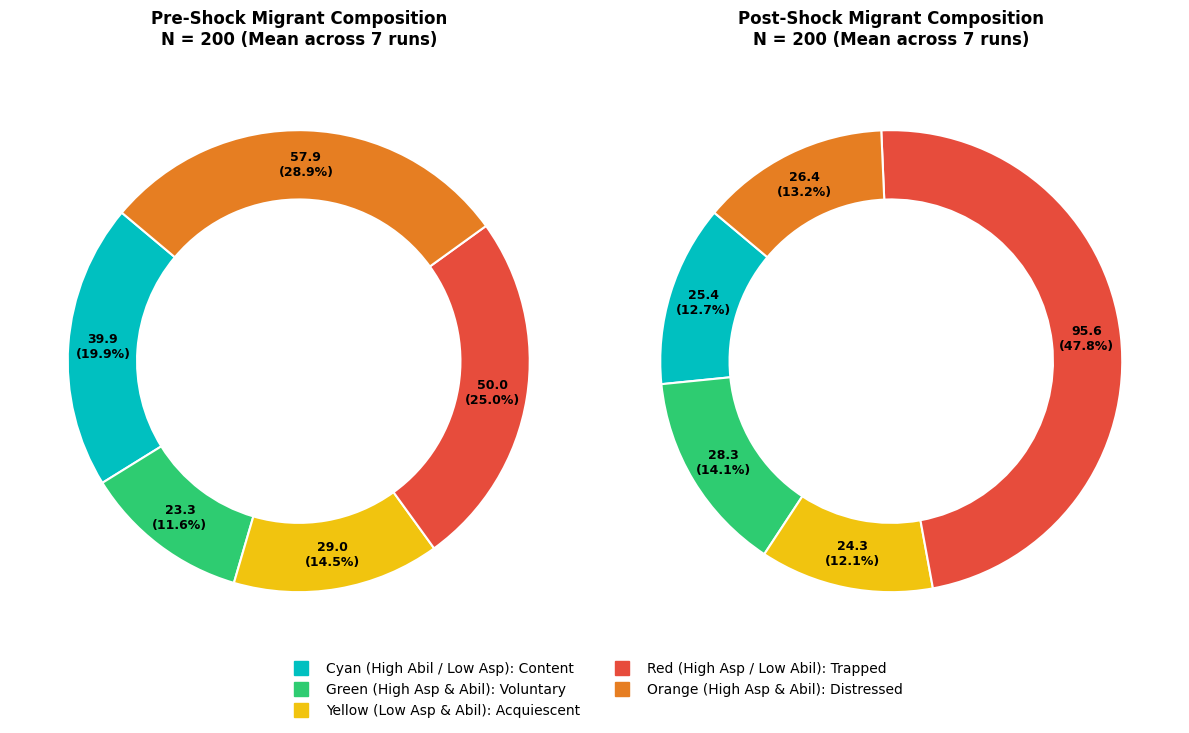

In [ ]:
import matplotlib.pyplot as plt

# Data from Picture1.png
labels = ['Cyan', 'Green', 'Yellow', 'Red', 'Orange']
colors_hex = ['#00c0c0', '#2ecc71', '#f1c40f', '#e74c3c', '#e67e22']
legend_labels = [
    'Cyan (High Abil / Low Asp): Content',
    'Green (High Asp & Abil): Voluntary',
    'Yellow (Low Asp & Abil): Acquiescent',
    'Red (High Asp / Low Abil): Trapped',
    'Orange (High Asp & Abil): Distressed'
]

pre_counts = [39.9, 23.3, 29.0, 50.0, 57.9]
pre_pcts = [19.9, 11.6, 14.5, 25.0, 28.9]

post_counts = [25.4, 28.3, 24.3, 95.6, 26.4]
post_pcts = [12.7, 14.1, 12.1, 47.8, 13.2]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 7))

# Helper to draw donut
def draw_donut(ax, counts, pcts, title):
    # Custom autopct function to show both count and percentage exactly like Picture1.png
    def make_autopct(values, percentages):
        def my_autopct(pct):
            # Find closest matching percentage index
            idx = min(range(len(percentages)), key=lambda i: abs(percentages[i] - pct))
            return f"{values[idx]:.1f}\n({pct:.1f}%)"
        return my_autopct

    wedges, texts, autotexts = ax.pie(
        counts,
        colors=colors_hex,
        autopct=make_autopct(counts, pcts),
        startangle=140,
        wedgeprops=dict(width=0.3, edgecolor='w', linewidth=1.5),
        pctdistance=0.85
    )
    for text in autotexts:
        text.set_fontsize(9)
        text.set_weight('bold')
    ax.set_title(title, fontsize=12, weight='bold', pad=20)

draw_donut(ax1, pre_counts, pre_pcts, "Pre-Shock Migrant Composition\nN = 200 (Mean across 7 runs)")
draw_donut(ax2, post_counts, post_pcts, "Post-Shock Migrant Composition\nN = 200 (Mean across 7 runs)")

# Create a common legend at the bottom
patches = [plt.plot([],[], marker="s", ms=10, ls="", color=colors_hex[i], label=legend_labels[i])[0] for i in range(len(colors_hex))]
fig.legend(handles=patches, loc='lower center', bbox_to_anchor=(0.5, 0.02), ncol=2, frameon=False, fontsize=10)

plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.show()